### Imports

In [48]:
# Interfaz
import re
import textwrap
import traceback
from datetime import datetime
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipyfilechooser import FileChooser
from IPython.display import clear_output, display
from matplotlib.backends.backend_pdf import PdfPages

import Funciones
import NNMF_GIF as NMF
import NNMF_GIF2 as CONMF
from MetricasRendimiento import MetricasRendimiento

%config InlineBackend.figure_format = 'svg'

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

In [60]:

TIPOS_VALIDOS = (int, float, str, bool)

def recolectar_parametros(prefijo, namespace):
    """Devuelve {nombre_sin_prefijo: valor} para las variables escalares que empiezan con prefijo."""
    return {
        nombre[len(prefijo):]: valor
        for nombre, valor in namespace.items()
        if nombre.startswith(prefijo) and isinstance(valor, TIPOS_VALIDOS)
    }

def figura_parametros(namespace=None):
    if namespace is None:
        namespace = globals()

    p_conmf = recolectar_parametros("conmf_", namespace)
    p_nmf = recolectar_parametros("nmf_", namespace)

    # Unión de claves, manteniendo el orden de definición (CONMF primero, luego las que solo están en NMF)
    claves = list(p_conmf) + [k for k in p_nmf if k not in p_conmf]

    filas = [[k, str(p_conmf.get(k, "—")), str(p_nmf.get(k, "—"))] for k in claves]

    fig, ax = plt.subplots(figsize=(8.27, 11.69))  # A4 vertical
    ax.axis("off")

    tabla = ax.table(
        cellText=filas,
        colLabels=["Parámetro", "CONMF", "NMF"],
        loc="upper center",
        cellLoc="center",
        colWidths=[0.5, 0.25, 0.25],
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.scale(1, 1.6)

    for j in range(3):
        tabla[0, j].set_facecolor("#4C72B0")
        tabla[0, j].set_text_props(color="white", weight="bold")

    for i in range(2, len(filas) + 1, 2):
        for j in range(3):
            tabla[i, j].set_facecolor("#F0F0F0")

    ax.set_title("Parámetros utilizados", fontsize=14, weight="bold", pad=20)
    return fig


CARPETA_SALIDA = Path.cwd() / "Resultados boxplots"
def guardar_pdf(fig_boxplot,nombre_pdf=None, namespace=None):
    """Página 1: boxplot. Página 2: parámetros detectados automáticamente.
    Guarda en la carpeta 'resultados boxplots'. Si no se indica nombre_pdf,
    usa la fecha y hora actual: DD-MM-YY-HH-MM-SS.pdf
    """
    if nombre_pdf is None:
        nombre_pdf = datetime.now().strftime("%d-%m-%y-%H-%M-%S") + ".pdf"
    elif not nombre_pdf.lower().endswith(".pdf"):
        nombre_pdf += ".pdf"

    CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)  # crea la carpeta si no existe
    ruta = CARPETA_SALIDA / nombre_pdf

    fig_par = figura_parametros(namespace)
    with PdfPages(ruta) as pdf:
        pdf.savefig(fig_boxplot, bbox_inches="tight")
        pdf.savefig(fig_par, bbox_inches="tight")
def boxplot_comparativo(ax, datos, titulo, etiquetas_grupos,color_nmf,color_conmf):
    """
    datos: lista de grupos; cada grupo es (lista_nmf, lista_conmf)
    etiquetas_grupos: nombre de cada grupo en el eje x
    """
    n_grupos = len(datos)
    ancho = 0.35
    posiciones_base = np.arange(n_grupos)

    nmf_data = [g[0] for g in datos]
    conmf_data = [g[1] for g in datos]

    bp1 = ax.boxplot(nmf_data, positions=posiciones_base - ancho/2 - 0.02,
                     widths=ancho, patch_artist=True, showfliers=True,notch=True)
    bp2 = ax.boxplot(conmf_data, positions=posiciones_base + ancho/2 + 0.02,
                     widths=ancho, patch_artist=True, showfliers=True,notch=True)

    for bp, color in [(bp1, color_nmf), (bp2, color_conmf)]:
        for caja in bp["boxes"]:
            caja.set(facecolor=color, alpha=0.7)
        for mediana in bp["medians"]:
            mediana.set(color="black", linewidth=1.5)

    ax.set_xticks(posiciones_base)
    ax.set_xticklabels(etiquetas_grupos)
    ax.set_ylabel("Error")
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.3)
    ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["NMF", "CONMF"])

### Carga de los archivos

In [2]:
fc_vocal_A = FileChooser('Señales VEC')
fc_vocal_A.layout = widgets.Layout(width='auto')
fc_vocal_A

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales VEC', filename='', title='', show_hidden=Fal…

In [3]:
lista_vocales_A = Path(fc_vocal_A.selected)
carpeta_base_vocal_A = lista_vocales_A.parent
with open(lista_vocales_A, "r", encoding="utf-8") as f:
    archivos_vocal_A = [linea.strip() for linea in f if linea.strip()]

In [23]:
fc_vocal_I = FileChooser('Señales VEC')
fc_vocal_I.layout = widgets.Layout(width='auto')
fc_vocal_I

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales VEC', filename='', title='', show_hidden=Fal…

In [28]:
lista_vocales_I = Path(fc_vocal_I.selected)
carpeta_base_vocal_I = lista_vocales_I.parent
with open(lista_vocales_I, "r", encoding="utf-8") as f:
    archivos_vocal_I = [linea.strip() for linea in f if linea.strip()]

### Definición de los parámetros del proceso

In [25]:

#========================================================================================================================================
# Elementos de CO-NMF

conmf_norma   = 'frobenius' # Opciones: frobenius, itakura-saito.
conmf_ventana = 'Rectangular' # Opciones: Rectangular, Hanning, Blackman, Hamming.

conmf_duracion_ventana = 5.5 # [ms]
conmf_desplazamiento   = 1 # en muestras
conmf_pre_iteraciones  = 0
conmf_iteraciones      = 250

conmf_T = 10    # Cuantas iteraciones hacia atrás miro para el criterio de parada
conmf_delta = 10e-4 # El δ usado para parar las iteraciones

conmf_p_filtro_speech = 12  # Orden del filtro del tracto para la voz
conmf_alfa_speech = 0.96 # El alfa del integrador
conmf_beta_speech = 0.55

conmf_p_filtro_acc = 12 # Orden del filtro del tracto para la señal de ACC
conmf_alfa_acc = 0.96 # El alfa del integrador para la señal de ACC
conmf_beta_acc = 0.55

conmf_pre_enfasis_speech = True
conmf_pre_enfasis_acc = True
conmf_guardar_proceso = False
conmf_normalizar_espectrogramas = True


#========================================================================================================================================
# Elementos de NMF

nmf_norma   = 'frobenius' # Opciones: frobenius, itakura-saito.
nmf_ventana = 'Rectangular' # Opciones: Rectangular, Hanning, Blackman, Hamming.

nmf_duracion_ventana = 5.5 # [ms]
nmf_desplazamiento   = 1 # en muestras
nmf_pre_iteraciones  = 0
nmf_iteraciones      = 250

nmf_T = 10    # Cuantas iteraciones hacia atrás miro para el criterio de parada
nmf_delta = 10e-4 # El δ usado para parar las iteraciones

nmf_p_filtro_speech = 12 # Orden del filtro del tracto
nmf_alfa_speech = 0.96 
nmf_beta_speech = 0.55

nmf_p_filtro_acc = 12 # Orden del filtro del tracto
nmf_alfa_acc = 0.96 
nmf_beta_acc = 0.55

nmf_pre_enfasis_speech = True
nmf_pre_enfasis_acc = True
nmf_guardar_proceso = False


### Cálculo de los errores

##### Proceso las señales

In [39]:
flujos_OVV_vocal_A  = []
dflujos_OVV_vocal_A = []
flujos_OVV_vocal_I  = []
dflujos_OVV_vocal_I = []
resultados_conmf_vocal_A = []
resultados_conmf_vocal_I = []

resultados_nmf_vocal_A_speech = []
resultados_nmf_vocal_I_speech = []
resultados_nmf_vocal_A_acc    = []
resultados_nmf_vocal_I_acc    = []
tiempos_analisis_vocal_A = []
tiempos_analisis_vocal_I = []

barra_progreso_A = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso vocal A:',
    bar_style='info',
    orientation='horizontal',
    style={'description_width': '120px'},
    layout=widgets.Layout(
        flex='0 0 200px'
    )
)

label_progreso_A = widgets.Label(
    value='0/0',
    layout=widgets.Layout(
        width='45px',
        flex='0 0 45px',
        margin='0 0 0 5px',
        text_align='right'
    )
)

grid_A = widgets.HBox(
    children=[barra_progreso_A, label_progreso_A],
    layout=widgets.Layout(
        width='100%',
        align_items='center'
    )
)

barra_progreso_I = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso vocal I:',
    bar_style='info',
    orientation='horizontal',
    style={'description_width': '120px'},
    layout=widgets.Layout(
        flex='0 0 200px'
    )
)

label_progreso_I = widgets.Label(
    value='0/0',
    layout=widgets.Layout(
        width='45px',
        flex='0 0 45px',
        margin='0 0 0 5px',
        text_align='right'
    )
)

grid_I = widgets.HBox(
    children=[barra_progreso_I, label_progreso_I],
    layout=widgets.Layout(
        width='100%',
        align_items='center'
    )
)

display(grid_A,grid_I)



total_archivos_A = len(archivos_vocal_A)
barra_progreso_A.max = total_archivos_A
barra_progreso_A.value = 0

label_progreso_A.value = f'0/{total_archivos_A}'
procesados_A = 0

total_archivos_I = len(archivos_vocal_I)
barra_progreso_I.max = total_archivos_I
barra_progreso_I.value = 0

label_progreso_I.value = f'0/{total_archivos_I}'
procesados_I = 0

for nombre in archivos_vocal_A:
    try:
        ruta_archivo = Path(carpeta_base_vocal_A) / nombre
        df = pd.read_csv(ruta_archivo, sep=',')
        fs_r = 8000
        tiempos = df['t_ms'].values
        t0_analisis = 5  # [ms]
        tf_analisis = 45 # [ms]

        mascara_tiempos  = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
        tiempos_analisis = tiempos[mascara_tiempos]
        flujo_OVV   = df['flujo_OVV'].values[mascara_tiempos]

        # ==================================================================
        señal_MBK  = df['MBK'].values
        señal_MBK  = señal_MBK - np.mean(señal_MBK)

        # El pasabajos en 1500 [Hz]
        señal_MBK,_,_     = Funciones.LP_Filter(señal_MBK, fs=fs_r, fc=1500, order=8)
        
        señal_ACC  = -df['ACC'].values
        señal_ACC  = señal_ACC - np.mean(señal_ACC)
        señal_EGG = df['MBK'].values
        señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
        señal_dEGG = np.gradient(señal_EGG)

        dflujo_OVV = np.gradient(flujo_OVV)

        # ==================================================================
        # CONMF
        resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,
                                        acelerometro=señal_ACC,
                                        dEGG=señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos = mascara_tiempos,
                                        fs=fs_r,
                                        ventana = conmf_ventana,
                                        duracion = conmf_duracion_ventana,
                                        hop = conmf_desplazamiento,
                                        pre_iteraciones= conmf_pre_iteraciones,
                                        iteraciones = conmf_iteraciones,
                                        T = conmf_T,
                                        delta = conmf_delta,
                                        p_filtro_speech = conmf_p_filtro_speech,
                                        alfa_speech = conmf_alfa_speech,
                                        p_filtro_acc = conmf_p_filtro_acc,
                                        alfa_acc = conmf_alfa_acc,
                                        beta_speech = conmf_beta_speech,
                                        beta_acc = conmf_beta_acc,
                                        pre_enfasis_speech = conmf_pre_enfasis_speech,
                                        pre_enfasis_acc = conmf_pre_enfasis_acc,
                                        guardar_proceso = conmf_guardar_proceso,
                                        normalizar_espectrogramas = conmf_normalizar_espectrogramas,
                                        nombre_archivo = nombre
                                        )

        # ==================================================================
        # NMF SPEECH
        resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,
                                        dEGG = señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos = mascara_tiempos,
                                        fs=fs_r,
                                        norma=nmf_norma,
                                        pre_iteraciones=nmf_pre_iteraciones,
                                        iteraciones=nmf_iteraciones,
                                        T = nmf_T,
                                        delta = nmf_delta,
                                        p_filtro=nmf_p_filtro_speech,
                                        alfa=nmf_alfa_speech,
                                        beta=nmf_beta_speech,
                                        pre_enfasis=nmf_pre_enfasis_speech,
                                        duracion=nmf_duracion_ventana,
                                        guardar_proceso=nmf_guardar_proceso,
                                        ventana = nmf_ventana
                                        )

        # ==================================================================
        # NMF ACC
        resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,
                                                dEGG = señal_dEGG,
                                                tiempos=tiempos,
                                                mascara_tiempos = mascara_tiempos,
                                                fs=fs_r,
                                                norma=nmf_norma,
                                                pre_iteraciones=nmf_pre_iteraciones,
                                                iteraciones=nmf_iteraciones,
                                                T = nmf_T,
                                                delta = nmf_delta,
                                                p_filtro=nmf_p_filtro_acc,
                                                alfa=nmf_alfa_acc,
                                                beta=nmf_beta_acc,
                                                pre_enfasis=nmf_pre_enfasis_acc,
                                                duracion=nmf_duracion_ventana,
                                                guardar_proceso=nmf_guardar_proceso,
                                                ventana = nmf_ventana
                                                )
        # ==================================================================
        flujos_OVV_vocal_A.append(flujo_OVV)
        dflujos_OVV_vocal_A.append(dflujo_OVV)
        tiempos_analisis_vocal_A.append(tiempos_analisis)
        resultados_conmf_vocal_A.append(resultado_CONMF)
        resultados_nmf_vocal_A_speech.append(resultado_NMF_speech)
        resultados_nmf_vocal_A_acc.append(resultado_NMF_acc)
    except Exception as e:
        print("Error con:",nombre)

    procesados_A += 1
    barra_progreso_A.value = procesados_A
    label_progreso_A.value = (f'{procesados_A}/{total_archivos_A}')

for nombre in archivos_vocal_I:
    try:
        ruta_archivo = Path(carpeta_base_vocal_I) / nombre
        df = pd.read_csv(ruta_archivo, sep=',')
        fs_r = 8000
        tiempos = df['t_ms'].values
        t0_analisis = 5  # [ms]
        tf_analisis = 45 # [ms]

        mascara_tiempos  = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
        tiempos_analisis = tiempos[mascara_tiempos]
        flujo_OVV   = df['flujo_OVV'].values[mascara_tiempos]

        # ==================================================================
        señal_MBK  = df['MBK'].values
        señal_MBK  = señal_MBK - np.mean(señal_MBK)

        # El pasabajos en 1500 [Hz]
        señal_MBK,_,_     = Funciones.LP_Filter(señal_MBK, fs=fs_r, fc=1500, order=8)
        
        señal_ACC  = -df['ACC'].values
        señal_ACC  = señal_ACC - np.mean(señal_ACC)
        señal_EGG = df['MBK'].values
        señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
        señal_dEGG = np.gradient(señal_EGG)

        dflujo_OVV = np.gradient(flujo_OVV)

        # ==================================================================
        # CONMF
        resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,
                                        acelerometro=señal_ACC,
                                        dEGG=señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos = mascara_tiempos,
                                        fs=fs_r,
                                        ventana = conmf_ventana,
                                        duracion = conmf_duracion_ventana,
                                        hop = conmf_desplazamiento,
                                        pre_iteraciones= conmf_pre_iteraciones,
                                        iteraciones = conmf_iteraciones,
                                        T = conmf_T,
                                        delta = conmf_delta,
                                        p_filtro_speech = conmf_p_filtro_speech,
                                        alfa_speech = conmf_alfa_speech,
                                        p_filtro_acc = conmf_p_filtro_acc,
                                        alfa_acc = conmf_alfa_acc,
                                        beta_speech = conmf_beta_speech,
                                        beta_acc = conmf_beta_acc,
                                        pre_enfasis_speech = conmf_pre_enfasis_speech,
                                        pre_enfasis_acc = conmf_pre_enfasis_acc,
                                        guardar_proceso = conmf_guardar_proceso,
                                        normalizar_espectrogramas = conmf_normalizar_espectrogramas,
                                        nombre_archivo = nombre
                                        )

        # ==================================================================
        # NMF SPEECH
        resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,
                                        dEGG = señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos = mascara_tiempos,
                                        fs=fs_r,
                                        norma=nmf_norma,
                                        pre_iteraciones=nmf_pre_iteraciones,
                                        iteraciones=nmf_iteraciones,
                                        T = nmf_T,
                                        delta = nmf_delta,
                                        p_filtro=nmf_p_filtro_speech,
                                        alfa=nmf_alfa_speech,
                                        beta=nmf_beta_speech,
                                        pre_enfasis=nmf_pre_enfasis_speech,
                                        duracion=nmf_duracion_ventana,
                                        guardar_proceso=nmf_guardar_proceso,
                                        ventana = nmf_ventana
                                        )

        # ==================================================================
        # NMF ACC
        resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,
                                                dEGG = señal_dEGG,
                                                tiempos=tiempos,
                                                mascara_tiempos = mascara_tiempos,
                                                fs=fs_r,
                                                norma=nmf_norma,
                                                pre_iteraciones=nmf_pre_iteraciones,
                                                iteraciones=nmf_iteraciones,
                                                T = nmf_T,
                                                delta = nmf_delta,
                                                p_filtro=nmf_p_filtro_acc,
                                                alfa=nmf_alfa_acc,
                                                beta=nmf_beta_acc,
                                                pre_enfasis=nmf_pre_enfasis_acc,
                                                duracion=nmf_duracion_ventana,
                                                guardar_proceso=nmf_guardar_proceso,
                                                ventana = nmf_ventana
                                                )
        # ==================================================================
        flujos_OVV_vocal_I.append(flujo_OVV)
        dflujos_OVV_vocal_I.append(dflujo_OVV)
        tiempos_analisis_vocal_I.append(tiempos_analisis)
        resultados_conmf_vocal_I.append(resultado_CONMF)
        resultados_nmf_vocal_I_speech.append(resultado_NMF_speech)
        resultados_nmf_vocal_I_acc.append(resultado_NMF_acc)
    except Exception as e:
        print("Error con:",nombre)

    procesados_I += 1
    barra_progreso_I.value = procesados_I
    label_progreso_I.value = (f'{procesados_I}/{total_archivos_I}')

### Error sobre el flujo glótico

In [43]:
errores_conmf_speech_vocal_A = []
errores_conmf_speech_vocal_I = []
errores_conmf_acc_vocal_I = []
errores_conmf_acc_vocal_A = []

errores_nmf_speech_vocal_A = []
errores_nmf_speech_vocal_I = []
errores_nmf_acc_vocal_A = []
errores_nmf_acc_vocal_I = []

for i in range(total_archivos_A):
    resultado_conmf = resultados_conmf_vocal_A[i]
    resultado_nmf_speech = resultados_nmf_vocal_A_speech[i]
    resultado_nmf_acc = resultados_nmf_vocal_A_acc[i]
    flujo_ovv = flujos_OVV_vocal_A[i]
    tiempo_analisis = tiempos_analisis_vocal_A[i]

    resultado_conmf.flujo1_speech  = Funciones.Detrend(resultado_conmf.tiempos_gve_speech,resultado_conmf.flujo1_speech)        
    resultado_conmf.flujo1_speech  = Funciones.Normalizar(resultado_conmf.flujo1_speech)
    resultado_conmf.dflujo1_speech = np.gradient(resultado_conmf.flujo1_speech)

    resultado_conmf.flujo1_acc     = Funciones.Detrend(resultado_conmf.tiempos_gve_acc,resultado_conmf.flujo1_acc)    
    resultado_conmf.flujo1_acc     = Funciones.Normalizar(resultado_conmf.flujo1_acc)  
    resultado_conmf.dflujo1_acc    = np.gradient(resultado_conmf.flujo1_acc)

    resultado_nmf_speech.flujo1 = Funciones.Detrend(resultado_nmf_speech.tiempos_gve,resultado_nmf_speech.flujo1)
    resultado_nmf_speech.flujo1 = Funciones.Normalizar(resultado_nmf_speech.flujo1)
    resultado_nmf_speech.dflujo1 = np.gradient(resultado_nmf_speech.flujo1)

        
    resultado_nmf_acc.flujo1 = Funciones.Detrend(resultado_nmf_acc.tiempos_gve,resultado_nmf_acc.flujo1)
    resultado_nmf_acc.flujo1 = Funciones.Normalizar(resultado_nmf_acc.flujo1)
    resultado_nmf_acc.dflujo1 = np.gradient(resultado_nmf_acc.flujo1)

    MR_NMF_speech_1   = MetricasRendimiento(flujo_ovv, resultado_nmf_speech.flujo1, tiempo_analisis)
    MR_NMF_acc_1      = MetricasRendimiento(flujo_ovv, resultado_nmf_acc.flujo1, tiempo_analisis)
    MR_CONMF_speech_1 = MetricasRendimiento(flujo_ovv, resultado_conmf.flujo1_speech, tiempo_analisis)
    MR_CONMF_acc_1    = MetricasRendimiento(flujo_ovv, resultado_conmf.flujo1_acc, tiempo_analisis)

    errores_conmf_speech_vocal_A.append(MR_CONMF_speech_1.Error)
    errores_conmf_acc_vocal_A.append(MR_CONMF_acc_1.Error)
    errores_nmf_speech_vocal_A.append(MR_NMF_speech_1.Error)
    errores_nmf_acc_vocal_A.append(MR_NMF_acc_1.Error)

for i in range(total_archivos_I):
    resultado_conmf = resultados_conmf_vocal_I[i]
    resultado_nmf_speech = resultados_nmf_vocal_I_speech[i]
    resultado_nmf_acc = resultados_nmf_vocal_I_acc[i]
    flujo_ovv = flujos_OVV_vocal_I[i]
    tiempo_analisis = tiempos_analisis_vocal_I[i]

    resultado_conmf.flujo1_speech  = Funciones.Detrend(resultado_conmf.tiempos_gve_speech,resultado_conmf.flujo1_speech)        
    resultado_conmf.flujo1_speech  = Funciones.Normalizar(resultado_conmf.flujo1_speech)
    resultado_conmf.dflujo1_speech = np.gradient(resultado_conmf.flujo1_speech)

    resultado_conmf.flujo1_acc     = Funciones.Detrend(resultado_conmf.tiempos_gve_acc,resultado_conmf.flujo1_acc)    
    resultado_conmf.flujo1_acc     = Funciones.Normalizar(resultado_conmf.flujo1_acc)  
    resultado_conmf.dflujo1_acc    = np.gradient(resultado_conmf.flujo1_acc)

    resultado_nmf_speech.flujo1 = Funciones.Detrend(resultado_nmf_speech.tiempos_gve,resultado_nmf_speech.flujo1)
    resultado_nmf_speech.flujo1 = Funciones.Normalizar(resultado_nmf_speech.flujo1)
    resultado_nmf_speech.dflujo1 = np.gradient(resultado_nmf_speech.flujo1)

        
    resultado_nmf_acc.flujo1 = Funciones.Detrend(resultado_nmf_acc.tiempos_gve,resultado_nmf_acc.flujo1)
    resultado_nmf_acc.flujo1 = Funciones.Normalizar(resultado_nmf_acc.flujo1)
    resultado_nmf_acc.dflujo1 = np.gradient(resultado_nmf_acc.flujo1)

    MR_NMF_speech_1   = MetricasRendimiento(flujo_ovv, resultado_nmf_speech.flujo1, tiempo_analisis)
    MR_NMF_acc_1      = MetricasRendimiento(flujo_ovv, resultado_nmf_acc.flujo1, tiempo_analisis)
    MR_CONMF_speech_1 = MetricasRendimiento(flujo_ovv, resultado_conmf.flujo1_speech, tiempo_analisis)
    MR_CONMF_acc_1    = MetricasRendimiento(flujo_ovv, resultado_conmf.flujo1_acc, tiempo_analisis)

    errores_conmf_speech_vocal_I.append(MR_CONMF_speech_1.Error)
    errores_conmf_acc_vocal_I.append(MR_CONMF_acc_1.Error)
    errores_nmf_speech_vocal_I.append(MR_NMF_speech_1.Error)
    errores_nmf_acc_vocal_I.append(MR_NMF_acc_1.Error)

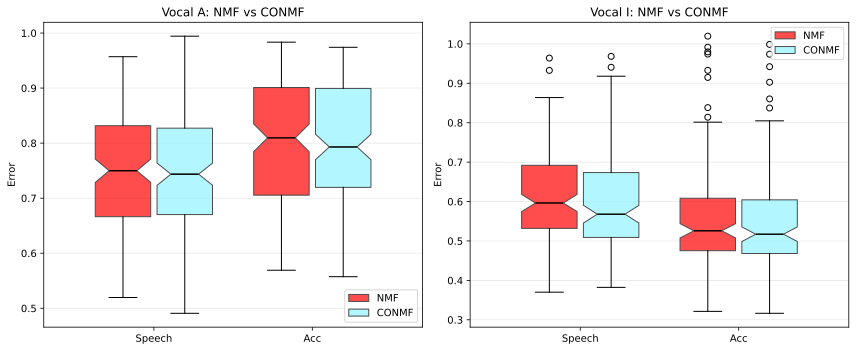

In [64]:
fig_box, ax = plt.subplots(1,2,figsize=(12, 5))

color_nmf = "#FF0000"
color_conmf = "#91F2FF"
boxplot_comparativo(
    ax[0],
    datos=[(errores_nmf_speech_vocal_A, errores_conmf_speech_vocal_A),
           (errores_nmf_acc_vocal_A,    errores_conmf_acc_vocal_A)],
    titulo="Vocal A: NMF vs CONMF",
    etiquetas_grupos=["Speech", "Acc"],color_nmf=color_nmf,color_conmf=color_conmf
)
boxplot_comparativo(
    ax[1],
    datos=[(errores_nmf_speech_vocal_I, errores_conmf_speech_vocal_I),
           (errores_nmf_acc_vocal_I,    errores_conmf_acc_vocal_I)],
    titulo="Vocal I: NMF vs CONMF",
    etiquetas_grupos=["Speech", "Acc"],color_nmf=color_nmf,color_conmf=color_conmf
)
fig_box.tight_layout()

plt.show()
#guardar_pdf(fig_box)

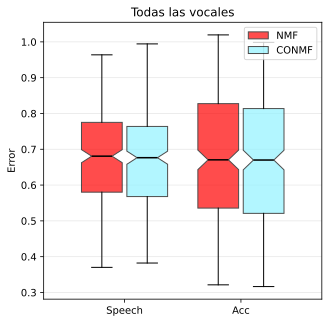

: 

In [ ]:
fig_box, ax = plt.subplots(figsize=(5, 5))

color_nmf = "#FF0000"
color_conmf = "#91F2FF"
boxplot_comparativo(
    ax,
    datos=[(errores_nmf_speech_vocal_A + errores_nmf_speech_vocal_I, errores_conmf_speech_vocal_A + errores_conmf_speech_vocal_I),
           (errores_nmf_acc_vocal_A + errores_nmf_acc_vocal_I, errores_conmf_acc_vocal_A + errores_conmf_acc_vocal_I)],
    titulo="Todas las vocales",
    etiquetas_grupos=["Speech", "Acc"],color_nmf=color_nmf,color_conmf=color_conmf
)